<a href="https://colab.research.google.com/github/thenishantsoni78/ggl-collab-projects/blob/main/embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mastering Transformer Architecture: Tokenization, Embeddings, & Attention

This notebook provides a deep dive into three foundational pillars of Modern NLP and Transformer-based models:
1. **Tokenization**: How text is broken down into manageable pieces.
2. **Embeddings**: How tokens are mapped to continuous vector spaces preserving semantic meaning.
3. **Attention Layer (Self-Attention)**: How models dynamically weigh the relationship between words in a sequence.

## 1. Tokenization

Tokenization is the process of converting a string of text into a sequence of smaller sub-units, called **tokens** (which can be words, characters, or subwords). Modern transformers use subword tokenization (like Byte-Pair Encoding or WordPiece) to handle out-of-vocabulary words elegantly.

Let's visualize this using the standard Hugging Face `transformers` library.

In [3]:
# Install necessary libraries
!pip install -q transformers tokenizers

In [2]:
from transformers import AutoTokenizer

# Initialize a standard BERT tokenizer
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

text = "Tokenization is the first step in training a Transformer!"
tokens = tokenizer.tokenize(text)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print(f"Original Text: \"{text}\"")
print(f"Tokens:        {tokens}")
print(f"Token IDs:     {token_ids}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Original Text: "Tokenization is the first step in training a Transformer!"
Tokens:        ['token', '##ization', 'is', 'the', 'first', 'step', 'in', 'training', 'a', 'transform', '##er', '!']
Token IDs:     [19204, 3989, 2003, 1996, 2034, 3357, 1999, 2731, 1037, 10938, 2121, 999]


## 2. Embeddings & Positional Encoding

Tokens are just discrete integers. An **Embedding Layer** acts as a lookup table that maps each token ID to a high-dimensional dense vector representing its semantic meaning.

Because Self-Attention processes all tokens in parallel, it has no inherent sense of sequence order. To fix this, we inject **Positional Encodings** into the embeddings. Let's visualize how word embeddings and positional encodings work.

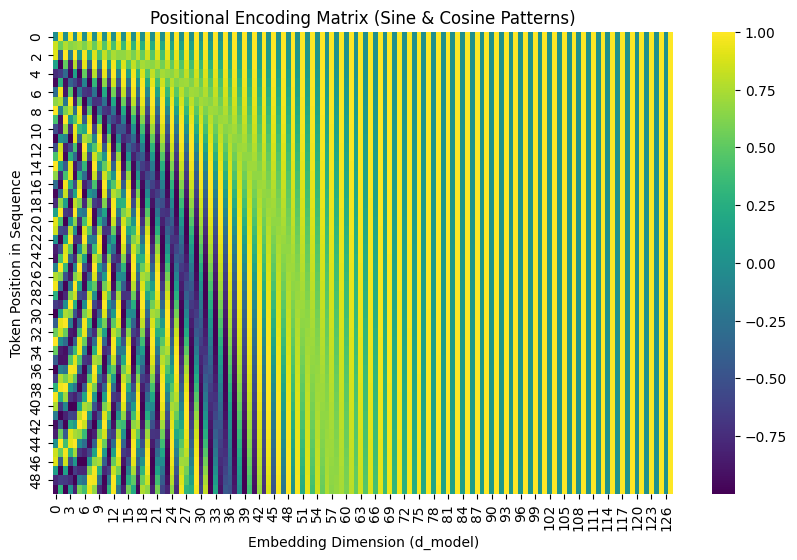

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate a toy Positional Encoding matrix
def get_positional_encoding(seq_len, d_model):
    pos_enc = np.zeros((seq_len, d_model))
    for pos in range(seq_len):
        for i in range(0, d_model, 2):
            pos_enc[pos, i] = np.sin(pos / (10000 ** (i / d_model)))
            pos_enc[pos, i + 1] = np.cos(pos / (10000 ** ((i) / d_model)))
    return pos_enc

seq_len = 50
d_model = 128
pe = get_positional_encoding(seq_len, d_model)

plt.figure(figsize=(10, 6))
sns.heatmap(pe, cmap='viridis')
plt.title("Positional Encoding Matrix (Sine & Cosine Patterns)")
plt.xlabel("Embedding Dimension (d_model)")
plt.ylabel("Token Position in Sequence")
plt.show()

## 3. The Self-Attention Layer

Self-Attention allows a model to look at other words in the input sequence to help get a better encoding for the word currently being processed.

### Mathematical Formulation:
$$ \text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V $$

Where:
* **Query ($Q$)**: What we are searching for.
* **Key ($K$)**: What we match against.
* **Value ($V$)**: The actual information content.
* **$d_k$**: The dimension of the keys (used for scaling to prevent vanishing gradients during softmax).

Attention Weights Matrix:
 [[0.3017341  0.30983964 0.3884262 ]
 [0.2450955  0.3801395  0.37476498]
 [0.29378855 0.2293217  0.4768897 ]]


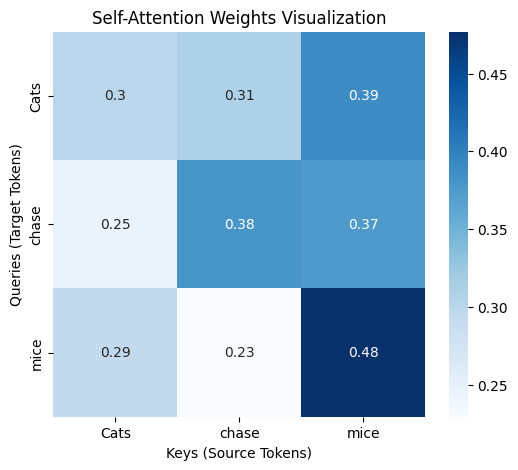

In [5]:
import torch
import torch.nn.functional as F

# Let's compute Self-Attention manually for a sequence of 3 tokens
# Sequence: "Cats chase mice"
seq_len = 3
d_k = 4 # Key/Query dimension
d_v = 4 # Value dimension

# Simulated word vectors (randomly initialized)
np.random.seed(42)
torch.manual_seed(42)

# Queries, Keys, and Values representation
Q = torch.randn(seq_len, d_k)
K = torch.randn(seq_len, d_k)
V = torch.randn(seq_len, d_v)

# Step 1: Compute scaled dot-product scores (QK^T / sqrt(d_k))
scores = torch.matmul(Q, K.T) / np.sqrt(d_k)

# Step 2: Apply softmax to get Attention Weights
attention_weights = F.softmax(scores, dim=-1)

# Step 3: Multiply by Values to get Context Vectors
context_vectors = torch.matmul(attention_weights, V)

print("Attention Weights Matrix:\n", attention_weights.numpy())

# Visualizing the Attention Weights
words = ["Cats", "chase", "mice"]
plt.figure(figsize=(6, 5))
sns.heatmap(attention_weights.detach().numpy(), annot=True, xticklabels=words, yticklabels=words, cmap='Blues')
plt.title("Self-Attention Weights Visualization")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")
plt.show()

## 4. Hands-on Exercise

**Exercise:** Below, write a short Python function `compute_attention(Q, K, V)` that implements the Scaled Dot-Product Attention formula, ensuring you scale by $\sqrt{d_k}$ and apply softmax properly.

In [8]:
def compute_attention(Q, K, V):
    # d_k is the dimension of the keys (last dimension of Q/K)
    d_k = Q.size(-1)

    # Step 1: Compute raw attention scores (Q multiplied by transpose of K)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(d_k)

    # Step 2: Apply softmax over the last dimension to get attention distribution
    attention_weights = F.softmax(scores, dim=-1)

    # Step 3: Multiply attention weights by V to obtain the context-aware representation
    output = torch.matmul(attention_weights, V)

    return output, attention_weights

# Test your implementation with toy data:
Q_test = torch.eye(3)
K_test = torch.eye(3)
V_test = torch.ones(3, 3)

out, weights = compute_attention(Q_test, K_test, V_test)
print("Calculated Output Matrix:\n", out)
print("Calculated Attention Weights:\n", weights)

Calculated Output Matrix:
 tensor([[1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000]])
Calculated Attention Weights:
 tensor([[0.4711, 0.2645, 0.2645],
        [0.2645, 0.4711, 0.2645],
        [0.2645, 0.2645, 0.4711]])
